In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import matplotlib.pyplot as plt
import numpy as np
import torchvision.transforms as transforms
import torch.nn.functional as F

In [2]:
# --- Configuration ---
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
BATCH_SIZE = 128 # Increased batch size slightly for ResNet
EPOCHS = 10
LR = 0.001
CLASSES = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

print(f"Using device: {DEVICE}")

Using device: cuda


In [3]:
# --- Data Preparation ---
def get_dataloaders():
    transform_train = transforms.Compose([
        transforms.RandomCrop(32, padding=4), # Data Augmentation helps ResNet
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
    ])

    transform_test = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
    ])

    train_dataset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform_train)
    train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)

    test_dataset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform_test)
    test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

    attack_loader = torch.utils.data.DataLoader(test_dataset, batch_size=1, shuffle=True)

    return train_loader, test_loader, attack_loader

In [4]:
# --- ResNet Definition ---
def get_cifar_resnet():
    # 1. Load standard ResNet18
    model = torchvision.models.resnet18(weights=None)

    # 2. Modify input layer for 32x32 images (kernel 7->3, stride 2->1)
    model.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)

    # 3. Remove the initial maxpool
    model.maxpool = nn.Identity()

    # 4. Modify output layer for 10 classes
    num_ftrs = model.fc.in_features
    model.fc = nn.Linear(num_ftrs, 10)

    return model

In [5]:
# --- 3. Training ---
def train_model(model, train_loader, criterion, optimizer):
    model.train()
    print("\n--- Starting Training ---")
    for epoch in range(EPOCHS):
        running_loss = 0.0
        for i, (inputs, labels) in enumerate(train_loader):
            inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        print(f'Epoch [{epoch+1}/{EPOCHS}], Loss: {running_loss / len(train_loader):.4f}')
    print('Finished Training')

In [6]:
# --- 4. Basic Evaluation ---
def basic_evaluation(model, test_loader):
    print("\n--- Basic Evaluation ---")
    model.eval()

    class_correct = list(0. for i in range(10))
    class_total = list(0. for i in range(10))
    total = 0
    correct = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

            c = (predicted == labels).squeeze()
            for i in range(len(labels)):
                label = labels[i]
                class_correct[label] += c[i].item()
                class_total[label] += 1

    print(f'Overall Clean Accuracy: {100 * correct / total:.2f} %')
    print("-" * 30)

In [7]:
# ---5. Adversarial Attack Logic (With ASR Calculation ---
def fgsm_attack(image, epsilon, data_grad):
    sign_data_grad = data_grad.sign()
    perturbed_image = image + epsilon * sign_data_grad
    perturbed_image = torch.clamp(perturbed_image, -1, 1)
    return perturbed_image

def run_attack_metrics(model, device, test_loader, epsilon, max_samples=500):
    """
    Returns:
    - asr (float): Attack Success Rate (0.0 to 1.0)
    - adv_examples (list): List of images for visualization
    """
    correct_clean_initial = 0 # How many the model got right initially
    successful_attacks = 0    # How many of those were successfully flipped
    adv_examples = []

    counter = 0
    for data, target in test_loader:
        if counter >= max_samples: break
        counter += 1

        data, target = data.to(device), target.to(device)
        data.requires_grad = True

        output = model(data)
        init_pred = output.max(1, keepdim=True)[1]

        # ASR is calculated only on images the model originally classified correctly
        if init_pred.item() != target.item():
            continue

        correct_clean_initial += 1 # Found a correctly classified image

        loss = F.cross_entropy(output, target)
        model.zero_grad()
        loss.backward()

        data_grad = data.grad.data
        perturbed_data = fgsm_attack(data, epsilon, data_grad)

        output = model(perturbed_data)
        final_pred = output.max(1, keepdim=True)[1]

        # If the prediction changed (and is now wrong), it's a successful attack
        if final_pred.item() != target.item():
            successful_attacks += 1

            if len(adv_examples) < 5:
                adv_ex = perturbed_data.squeeze().detach().cpu().numpy()
                orig_ex = data.squeeze().detach().cpu().numpy()
                adv_examples.append((init_pred.item(), final_pred.item(), orig_ex, adv_ex))

    # Calculate ASR
    if correct_clean_initial > 0:
        asr = successful_attacks / float(correct_clean_initial)
    else:
        asr = 0.0

    print(f"Epsilon: {epsilon:<5} | Clean Hits: {correct_clean_initial} | Successful Attacks: {successful_attacks} | ASR: {asr*100:.2f}%")
    return asr, adv_examples

In [8]:
# --- 6. Advanced Evaluation (ASR Curve) ---
def advanced_evaluation(model, test_loader, attack_loader):
    print("\n--- Advanced Evaluation (ASR) ---")
    model.eval()

    # B. ASR Curve
    epsilons = [0, 0.05, 0.1, 0.15, 0.2, 0.3]
    asrs = []

    print("Generating ASR Curve (Attack Success Rate)...")
    for eps in epsilons:
        asr_val, _ = run_attack_metrics(model, DEVICE, attack_loader, eps, max_samples=500)
        asrs.append(asr_val)

    # Plot ASR Curve
    plt.figure(figsize=(8, 6))
    plt.plot(epsilons, asrs, "r*-") # 'r' for red color
    plt.yticks(np.arange(0, 1.1, step=0.1))
    plt.xticks(np.arange(0, .35, step=0.05))
    plt.title("Attack Success Rate (ASR) vs. Epsilon")
    plt.xlabel("Epsilon (Perturbation Magnitude)")
    plt.ylabel("ASR (Attack Success Rate)")
    plt.grid()
    plt.show()

In [9]:
# --- 7. Visualization Helper ---
def imshow_high_quality(img, ax, title=None, is_noise=False):
    if not is_noise:
        img = img / 2 + 0.5
    npimg = img
    if is_noise:
        ax.imshow(np.transpose(npimg, (1, 2, 0)), interpolation='nearest', cmap='coolwarm')
    else:
        ax.imshow(np.transpose(npimg, (1, 2, 0)), interpolation='nearest')
    ax.axis('off')
    if title: ax.set_title(title, fontsize=10)

def visualize_attacks(examples):
    plt.figure(figsize=(10, 8), dpi=100)
    for i in range(len(examples)):
        orig_label, adv_label, orig_img, adv_img = examples[i]

        noise = adv_img - orig_img
        noise = (noise - noise.min()) / (noise.max() - noise.min())

        ax1 = plt.subplot(len(examples), 3, 3*i + 1)
        imshow_high_quality(orig_img, ax1, title=f"Orig: {CLASSES[orig_label]}")

        ax2 = plt.subplot(len(examples), 3, 3*i + 2)
        imshow_high_quality(noise, ax2, title="Noise", is_noise=True)

        ax3 = plt.subplot(len(examples), 3, 3*i + 3)
        imshow_high_quality(adv_img, ax3, title=f"Adv: {CLASSES[adv_label]}")
    plt.tight_layout()
    plt.show()

100%|██████████| 170M/170M [00:25<00:00, 6.61MB/s]



--- Starting Training ---
Epoch [1/10], Loss: 1.3330
Epoch [2/10], Loss: 0.8609
Epoch [3/10], Loss: 0.6622
Epoch [4/10], Loss: 0.5638
Epoch [5/10], Loss: 0.4888
Epoch [6/10], Loss: 0.4400
Epoch [7/10], Loss: 0.3939
Epoch [8/10], Loss: 0.3570
Epoch [9/10], Loss: 0.3279
Epoch [10/10], Loss: 0.3006
Finished Training

--- Basic Evaluation ---
Overall Clean Accuracy: 86.29 %
------------------------------

--- Advanced Evaluation (ASR) ---
Generating ASR Curve (Attack Success Rate)...
Epsilon: 0     | Clean Hits: 424 | Successful Attacks: 0 | ASR: 0.00%
Epsilon: 0.05  | Clean Hits: 436 | Successful Attacks: 414 | ASR: 94.95%
Epsilon: 0.1   | Clean Hits: 441 | Successful Attacks: 420 | ASR: 95.24%
Epsilon: 0.15  | Clean Hits: 431 | Successful Attacks: 408 | ASR: 94.66%
Epsilon: 0.2   | Clean Hits: 438 | Successful Attacks: 389 | ASR: 88.81%
Epsilon: 0.3   | Clean Hits: 429 | Successful Attacks: 382 | ASR: 89.04%


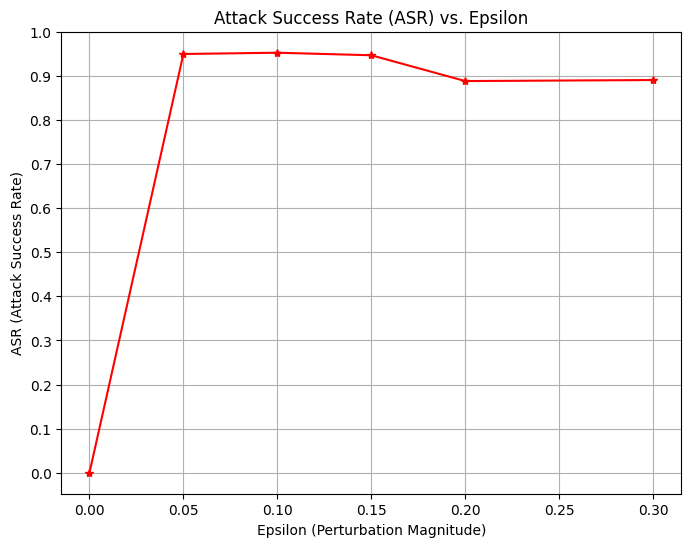


Generating final visual examples...
Epsilon: 0.1   | Clean Hits: 82 | Successful Attacks: 80 | ASR: 97.56%


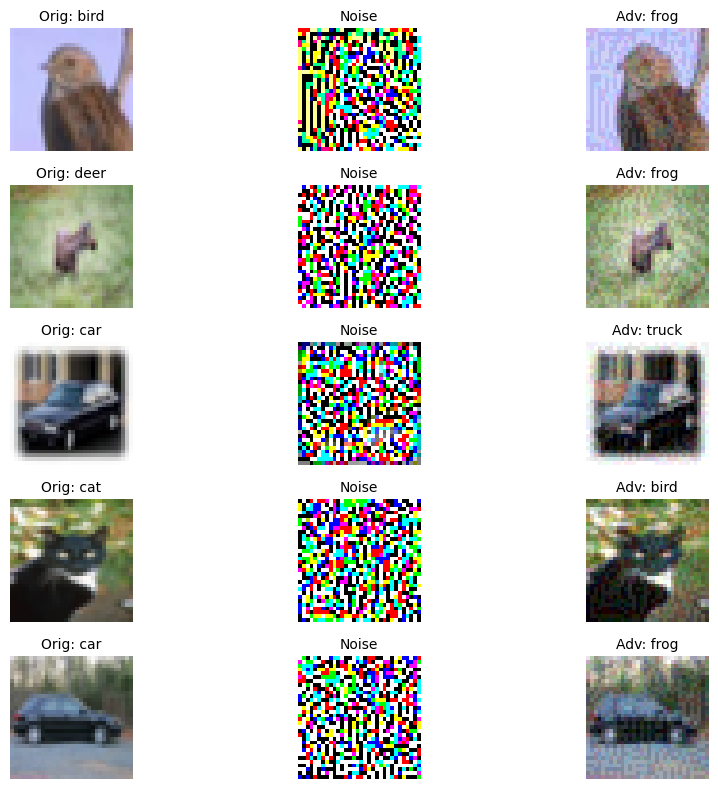

In [10]:
# --- Main Execution ---
if __name__ == "__main__":
    train_loader, test_loader, attack_loader = get_dataloaders()

    # 1. Train
    model = get_cifar_resnet().to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LR)
    train_model(model, train_loader, criterion, optimizer)

    # 2. Basic Clean Evaluation
    basic_evaluation(model, test_loader)

    # 3. Advanced Evaluation (ASR Curve)
    advanced_evaluation(model, test_loader, attack_loader)

    # 4. Final Visual Check
    print("\nGenerating final visual examples...")
    _, examples = run_attack_metrics(model, DEVICE, attack_loader, epsilon=0.1, max_samples=100)
    visualize_attacks(examples)